## Task 1 : Load MNIST and train a baseline CNN. Report the clean test accuracy.

In [8]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader
import numpy as np
from keras.datasets import mnist

# Set manual seed
torch.manual_seed(42)
np.random.seed(42)

# Task 1: Load MNIST using Keras and prepare PyTorch DataLoaders
(x_train_raw, y_train_raw), (x_test_raw, y_test_raw) = mnist.load_data()

# Scale pixel values to [0, 1] and add channel dimension
x_train_raw = x_train_raw.astype(np.float32) / 255.0
x_test_raw = x_test_raw.astype(np.float32) / 255.0

x_train_raw = np.expand_dims(x_train_raw, axis=1)
x_test_raw = np.expand_dims(x_test_raw, axis=1)

# Convert to PyTorch tensors
x_train_tensor = torch.tensor(x_train_raw)
y_train_tensor = torch.tensor(y_train_raw, dtype=torch.long)
x_test_tensor = torch.tensor(x_test_raw)
y_test_tensor = torch.tensor(y_test_raw, dtype=torch.long)

train_dataset = TensorDataset(x_train_tensor, y_train_tensor)
test_dataset = TensorDataset(x_test_tensor, y_test_tensor)

train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=64, shuffle=False)

# Define the CNN architecture (two convolution layers + two fully connected layers)
class BaselineCNN(nn.Module):
    def __init__(self):
        super(BaselineCNN, self).__init__()
        self.conv1 = nn.Conv2d(1, 32, kernel_size=3, padding=1)
        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, padding=1)
        self.pool = nn.MaxPool2d(2, 2)
        self.fc1 = nn.Linear(64 * 7 * 7, 128)
        self.fc2 = nn.Linear(128, 10)
        self.relu = nn.ReLU()

    def forward(self, x):
        x = self.pool(self.relu(self.conv1(x)))
        x = self.pool(self.relu(self.conv2(x)))
        x = x.view(-1, 64 * 7 * 7)
        x = self.relu(self.fc1(x))
        x = self.fc2(x)
        return x

# Initialize model, optimizer, and loss
device = torch.device("cpu")
model = BaselineCNN().to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

# Train Baseline Model
epochs = 2
for epoch in range(epochs):
    model.train()
    for data, target in train_loader:
        data, target = data.to(device), target.to(device)
        optimizer.zero_grad()
        output = model(data)
        loss = criterion(output, target)
        loss.backward()
        optimizer.step()

# Evaluate Clean Test Accuracy
model.eval()
correct = 0
total = 0
with torch.no_grad():
    for data, target in test_loader:
        data, target = data.to(device), target.to(device)
        outputs = model(data)
        _, predicted = torch.max(outputs.data, 1)
        total += target.size(0)
        correct += (predicted == target).sum().item()

clean_accuracy = 100 * correct / total
print(f"Training baseline CNN (2 epochs)... done.")
print(f"Clean test accuracy: {clean_accuracy:.1f} %")

Training baseline CNN (2 epochs)... done.
Clean test accuracy: 98.8 %


## Task 2: Implement the FGSM attack

In [17]:
def fgsm_attack(image, epsilon, data_grad):
    sign_data_grad = data_grad.sign()
    perturbed_image = image + epsilon * sign_data_grad
    perturbed_image = torch.clamp(perturbed_image, 0, 1)
    return perturbed_image

def evaluate_fgsm(model, device, test_loader, epsilon, max_samples=1000):
    model.eval()
    correct = 0
    total_samples = 0
    for data, target in test_loader:
        data, target = data.to(device), target.to(device)
        data.requires_grad = True
        output = model(data)
        loss = criterion(output, target)
        model.zero_grad()
        loss.backward()
        data_grad = data.grad.data
        perturbed_data = fgsm_attack(data, epsilon, data_grad)

        with torch.no_grad():
            output_perturbed = model(perturbed_data)
            _, final_pred = torch.max(output_perturbed.data, 1)
            correct += (final_pred == target).sum().item()

        total_samples += data.size(0)
        if total_samples >= max_samples:
            break
    return 100 * correct / total_samples

## Task 3: Implement the PGD attack

In [18]:
def pgd_attack(model, images, labels, epsilon, alpha=None, iters=10):
    if alpha is None:
        alpha = epsilon / 4
    perturbed_images = images.clone().detach() + torch.FloatTensor(*images.shape).uniform_(-epsilon, epsilon).to(device)
    perturbed_images = torch.clamp(perturbed_images, 0, 1)

    for i in range(iters):
        perturbed_images.requires_grad = True
        outputs = model(perturbed_images)
        loss = criterion(outputs, labels)
        model.zero_grad()
        loss.backward()

        with torch.no_grad():
            grad = perturbed_images.grad.data
            perturbed_images = perturbed_images + alpha * grad.sign()
            eta = torch.clamp(perturbed_images - images, min=-epsilon, max=epsilon)
            perturbed_images = torch.clamp(images + eta, min=0, max=1).detach()

    return perturbed_images

def evaluate_pgd(model, device, test_loader, epsilon, max_samples=1000):
    model.eval()
    correct = 0
    total_samples = 0
    for data, target in test_loader:
        data, target = data.to(device), target.to(device)
        perturbed_data = pgd_attack(model, data, target, epsilon)

        with torch.no_grad():
            output_perturbed = model(perturbed_data)
            _, final_pred = torch.max(output_perturbed.data, 1)
            correct += (final_pred == target).sum().item()

        total_samples += data.size(0)
        if total_samples >= max_samples:
            break
    return 100 * correct / total_samples

## Task 4:

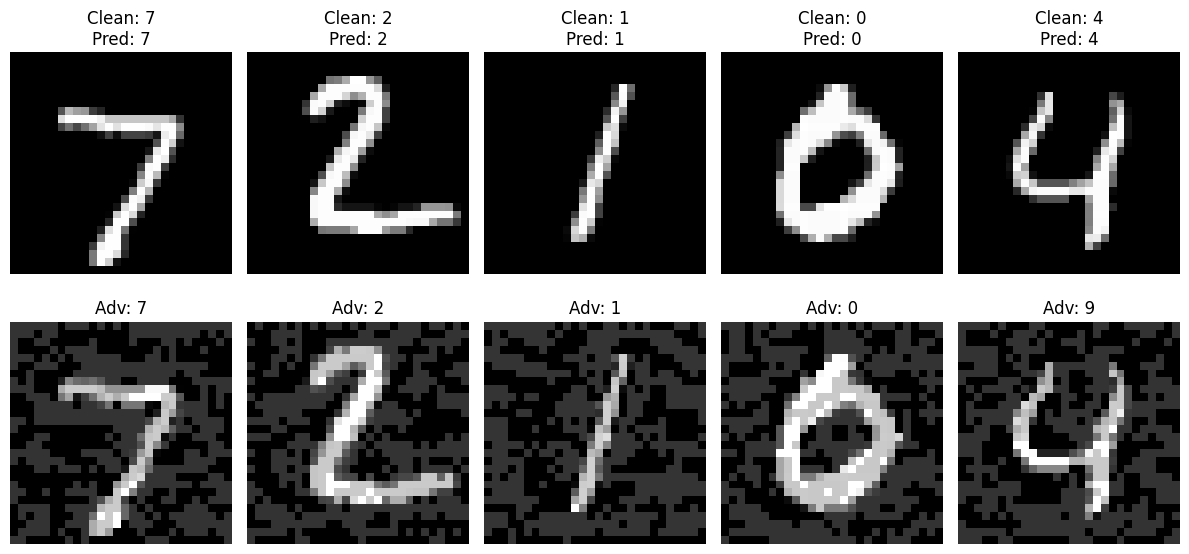

In [9]:
import matplotlib.pyplot as plt
import torch

# Ensure the model and dataloaders are loaded before plotting
if 'model' not in globals() or 'test_loader' not in globals():
    print("Error: 'model' or 'test_loader' is not defined. Please run the Task 1 cell (aadd565e) first to train and define your model!")
else:
    # Task 4: Display 5 clean digits and their FGSM adversarial versions (epsilon = 0.20)
    model.eval()
    fig, axes = plt.subplots(2, 5, figsize=(12, 6))

    data_iter = iter(test_loader)
    images, labels = next(data_iter)
    images, labels = images.to(device), labels.to(device)
    images.requires_grad = True

    outputs = model(images)
    loss = criterion(outputs, labels)
    model.zero_grad()
    loss.backward()
    data_grad = images.grad.data

    perturbed_images = fgsm_attack(images, 0.20, data_grad)
    outputs_perturbed = model(perturbed_images)
    _, clean_preds = torch.max(outputs.data, 1)
    _, perturbed_preds = torch.max(outputs_perturbed.data, 1)

    for idx in range(5):
        # Plot clean
        ax_clean = axes[0, idx]
        ax_clean.imshow(images[idx].squeeze().detach().cpu().numpy(), cmap='gray')
        ax_clean.set_title(f"Clean: {labels[idx].item()}\nPred: {clean_preds[idx].item()}")
        ax_clean.axis('off')

        # Plot adversarial
        ax_adv = axes[1, idx]
        ax_adv.imshow(perturbed_images[idx].squeeze().detach().cpu().numpy(), cmap='gray')
        ax_adv.set_title(f"Adv: {perturbed_preds[idx].item()}")
        ax_adv.axis('off')

    plt.tight_layout()
    plt.savefig('clean_vs_adversarial.png')
    plt.show()

## Task 5: Apply adversarial training

In [10]:
# Task 5: Apply adversarial training
if 'BaselineCNN' not in globals() or 'train_loader' not in globals():
    print("Error: 'BaselineCNN' or 'train_loader' is not defined. Please run the Task 1 cell (aadd565e) first to define the architecture and train the baseline!")
else:
    adv_model = BaselineCNN().to(device)
    adv_optimizer = optim.Adam(adv_model.parameters(), lr=0.001)

    # Train adversarially on a 50:50 mix of clean and FGSM (epsilon=0.20) images
    for epoch in range(epochs):
        adv_model.train()
        for data, target in train_loader:
            data, target = data.to(device), target.to(device)

            # Standard pass to obtain grads for FGSM generation
            data.requires_grad = True
            outputs_temp = adv_model(data)
            loss_temp = criterion(outputs_temp, target)
            adv_model.zero_grad()
            loss_temp.backward()
            data_grad = data.grad.data

            # Split dataset in half
            batch_size = data.size(0)
            half_batch = batch_size // 2

            # Build a mixed batch of clean and adversarial images
            perturbed_data = fgsm_attack(data, 0.20, data_grad)
            mixed_data = torch.cat([data[:half_batch], perturbed_data[half_batch:]], dim=0).detach()

            adv_optimizer.zero_grad()
            outputs = adv_model(mixed_data)
            loss = criterion(outputs, target)
            loss.backward()
            adv_optimizer.step()

## Task 6: Evaluate models, plot accuracy vs epsilon, and tabulate results


--- PART A: Baseline Model under Attack ---
EPSILON	FGSM_ACC	PGD_ACC
-------------------------------
0.00	98.8 %	98.8 %
0.05	94.3 %	93.8 %
0.10	86.4 %	79.8 %
0.20	45.5 %	3.8 %
0.30	9.5 %	0.0 %
-------------------------------
Attack success (eps=0.20): FGSM 54.5 %, PGD 96.2 %

--- PART B: Adversarial Training (Defence) ---
MODEL		CLEAN	FGSM(0.20)	PGD(0.20)
----------------------------------------------------
Baseline	98.8 %	45.5 %	3.8 %
Adversarially	97.9 %	95.6 %	3.5 %
----------------------------------------------------
Clean accuracy change: -0.9 %
FGSM robustness gain: +50.1 %
PGD gain: -0.3 %


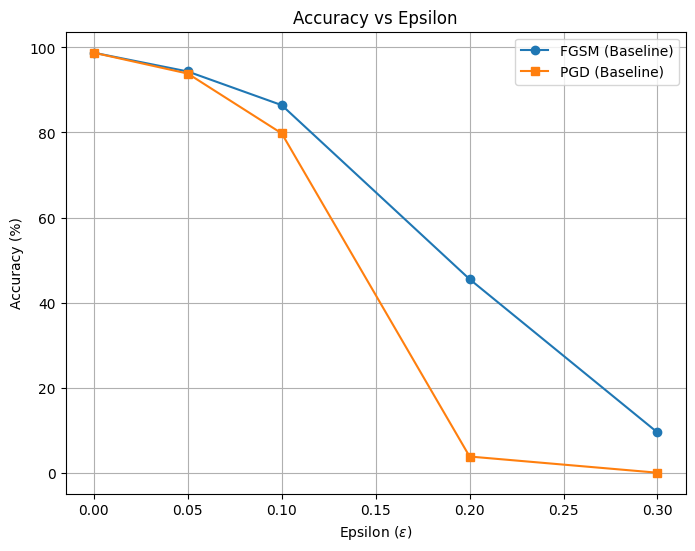

In [19]:
if 'clean_accuracy' not in globals() or 'model' not in globals() or 'adv_model' not in globals():
    print("Error: Necessary models or variables are missing. Please ensure cells aadd565e and 28b56330 have run successfully first!")
else:
    epsilons = [0.00, 0.05, 0.10, 0.20, 0.30]
    baseline_fgsm_accs = []
    baseline_pgd_accs = []

    for eps in epsilons:
        if eps == 0.0:
            baseline_fgsm_accs.append(clean_accuracy)
            baseline_pgd_accs.append(clean_accuracy)
        else:
            baseline_fgsm_accs.append(evaluate_fgsm(model, device, test_loader, eps))
            baseline_pgd_accs.append(evaluate_pgd(model, device, test_loader, eps))

    # Evaluate adversarially trained model on epsilon = 0.20
    adv_clean_acc = evaluate_fgsm(adv_model, device, test_loader, 0.0)
    adv_fgsm_20_acc = evaluate_fgsm(adv_model, device, test_loader, 0.20)
    adv_pgd_20_acc = evaluate_pgd(adv_model, device, test_loader, 0.20)

    print("\n--- PART A: Baseline Model under Attack ---")
    print(f"EPSILON\tFGSM_ACC\tPGD_ACC")
    print("-------------------------------")
    for eps, fgsm, pgd in zip(epsilons, baseline_fgsm_accs, baseline_pgd_accs):
        print(f"{eps:.2f}\t{fgsm:.1f} %\t{pgd:.1f} %")
    print("-------------------------------")
    print(f"Attack success (eps=0.20): FGSM {100-baseline_fgsm_accs[3]:.1f} %, PGD {100-baseline_pgd_accs[3]:.1f} %")

    print("\n--- PART B: Adversarial Training (Defence) ---")
    print(f"MODEL\t\tCLEAN\tFGSM(0.20)\tPGD(0.20)")
    print("----------------------------------------------------")
    print(f"Baseline\t{clean_accuracy:.1f} %\t{baseline_fgsm_accs[3]:.1f} %\t{baseline_pgd_accs[3]:.1f} %")
    print(f"Adversarially\t{adv_clean_acc:.1f} %\t{adv_fgsm_20_acc:.1f} %\t{adv_pgd_20_acc:.1f} %")
    print("----------------------------------------------------")
    print(f"Clean accuracy change: {adv_clean_acc - clean_accuracy:+.1f} %")
    print(f"FGSM robustness gain: {adv_fgsm_20_acc - baseline_fgsm_accs[3]:+.1f} %")
    print(f"PGD gain: {adv_pgd_20_acc - baseline_pgd_accs[3]:+.1f} %")

    # Save the plot of Accuracy vs Epsilon using raw string for LaTeX formatting
    plt.figure(figsize=(8, 6))
    plt.plot(epsilons, baseline_fgsm_accs, 'o-', label='FGSM (Baseline)')
    plt.plot(epsilons, baseline_pgd_accs, 's-', label='PGD (Baseline)')
    plt.xlabel(r'Epsilon ($\epsilon$)')
    plt.ylabel('Accuracy (%)')
    plt.title('Accuracy vs Epsilon')
    plt.legend()
    plt.grid(True)
    plt.savefig('accuracy_vs_epsilon.png')
    plt.show()